# Mouse vascular: cell-type annotation (stage 04c)

Every cluster of the re-integrated vascular lineage is assigned one cell type (or EXCLUDE). Labels are the vocabulary in resources/annotation_vocabulary.yaml.

Clustering: `data/interim/latent_mouse_vascular.h5ad`, column `leiden_scVI_3.0`. Decisions: `resources/annotations/mouse_vascular.csv`, one
row per cluster with the markers that justify the label in `note`. Nothing in this
notebook assigns a label; it shows the evidence the table was decided from.

In [1]:
import warnings
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc

# Notebook kernels start in notebooks/annotation/, so the repo root is two levels up.
REPO = Path("../..").resolve()
if not (REPO / "resources/annotations").is_dir():
    raise FileNotFoundError(f"{REPO} is not the repository root")
SPECIES, LEVEL, RESOLUTION = "mouse", "vascular", "leiden_scVI_3.0"
OBJECT = REPO / "data/interim/latent_mouse_vascular.h5ad"
TABLE = REPO / "resources/annotations/mouse_vascular.csv"
PANEL = ['Pecam1', 'Flt1', 'Cldn5', 'Cdh5', 'Pdgfrb', 'Rgs5', 'Acta2', 'Cdh1', 'Pdgfra', 'Ptprc', 'Sox6', 'Prox1', 'Lyve1']
sc.settings.set_figure_params(dpi=80, frameon=False)
pd.set_option("display.max_colwidth", 200)

## 1. The committed table

In [2]:
table = pd.read_csv(TABLE, dtype={"cluster": str})
table.set_index("cluster")

,label,n_cells,res,note
cluster,,,,
0,EXCLUDE,153,leiden_scVI_3.0,"EXCLUDE: doublet score med 0.90 (level q75 0.04), genes med 1939 (level q25 914), 0.44 co-express 2+ lineage panels (level 0.19); panels: vascular 0.92, endometrial_fibroblasts 0.35, perimetrium 0.10"
1,endothelial_blood,143,leiden_scVI_3.0,"Pecam1 0.94; Flt1 0.97; Cldn5 0.24; Cdh5 0.76 | top vs level: Top2a 0.80, Diaph3 0.80, Auts2 0.82"
2,endothelial_blood,91,leiden_scVI_3.0,"Pecam1 0.82; Flt1 0.89; Cldn5 0.02; Cdh5 0.53 | top vs level: Rundc3b 0.86, Abcb1a 0.75, Dach1 0.85"
3,endothelial_blood,201,leiden_scVI_3.0,"Pecam1 0.92; Flt1 0.94; Cldn5 0.04; Cdh5 0.67 | top vs level: Top2a 0.88, Diaph3 0.85, Mki67 0.76"
4,EXCLUDE,127,leiden_scVI_3.0,"EXCLUDE: doublet score med 0.00 (level q75 0.04), genes med 1295 (level q25 914), 0.49 co-express 2+ lineage panels (level 0.19); panels: vascular 0.94, perimetrium 0.35, endometrial_fibroblasts 0.11"
5,endothelial_blood,241,leiden_scVI_3.0,"Pecam1 0.79; Flt1 0.75; Cldn5 0.02; Cdh5 0.46 | top vs level: Prkg1 0.82, Zfp521 0.80, Rora 0.81"
6,endothelial_blood,52,leiden_scVI_3.0,"Pecam1 0.90; Flt1 0.85; Cldn5 0.02; Cdh5 0.63 | top vs level: Kif11 0.77, Lockd 0.65, Cenpe 0.67"
7,endothelial_blood,147,leiden_scVI_3.0,"Pecam1 0.86; Flt1 0.91; Cldn5 0.03; Cdh5 0.61 | top vs level: Diaph3 0.86, Rad51b 0.79, Top2a 0.78"
8,endothelial_blood,161,leiden_scVI_3.0,"Pecam1 0.80; Flt1 0.75; Cldn5 0.02; Cdh5 0.33 | top vs level: Ebf1 0.79, Etl4 0.68, Nrp1 0.64"


## 2. The clustered object (must carry exactly the clusters in the table)

In [3]:
adata = ad.read_h5ad(OBJECT)
adata.obs["cluster"] = adata.obs[RESOLUTION].astype(str)
in_object, in_table = set(adata.obs["cluster"]), set(table["cluster"])
if in_object != in_table:
    raise ValueError(f"cluster sets differ: object-only {sorted(in_object - in_table)}, "
                     f"table-only {sorted(in_table - in_object)}")
labels = table.set_index("cluster")["label"]
adata.obs["label"] = adata.obs["cluster"].map(labels).astype("category")
print(adata.n_obs, "nuclei;", len(in_object), "clusters")
print(adata.obs["label"].value_counts().to_dict())

3962 nuclei; 33 clusters
{'endothelial_blood': 3487, 'EXCLUDE': 475}


In [4]:
# Expression for the dot plot: CP10K log1p from raw counts.
counts = adata.layers["counts"] if "counts" in adata.layers else adata.X
expr = ad.AnnData(X=counts.copy(), obs=adata.obs[["cluster", "label"]].copy(),
                  var=adata.var[[]].copy())
sc.pp.normalize_total(expr, target_sum=1e4)
sc.pp.log1p(expr)
genes = [g for g in PANEL if g in expr.var_names]
missing = sorted(set(PANEL) - set(genes))
if missing:
    print("not in this object:", missing)

## 3. Marker dot plot by cluster

Dot size is the fraction of nuclei in which the gene is detected, colour the mean
log1p CP10K. Clusters are grouped by their label; EXCLUDE clusters are last.

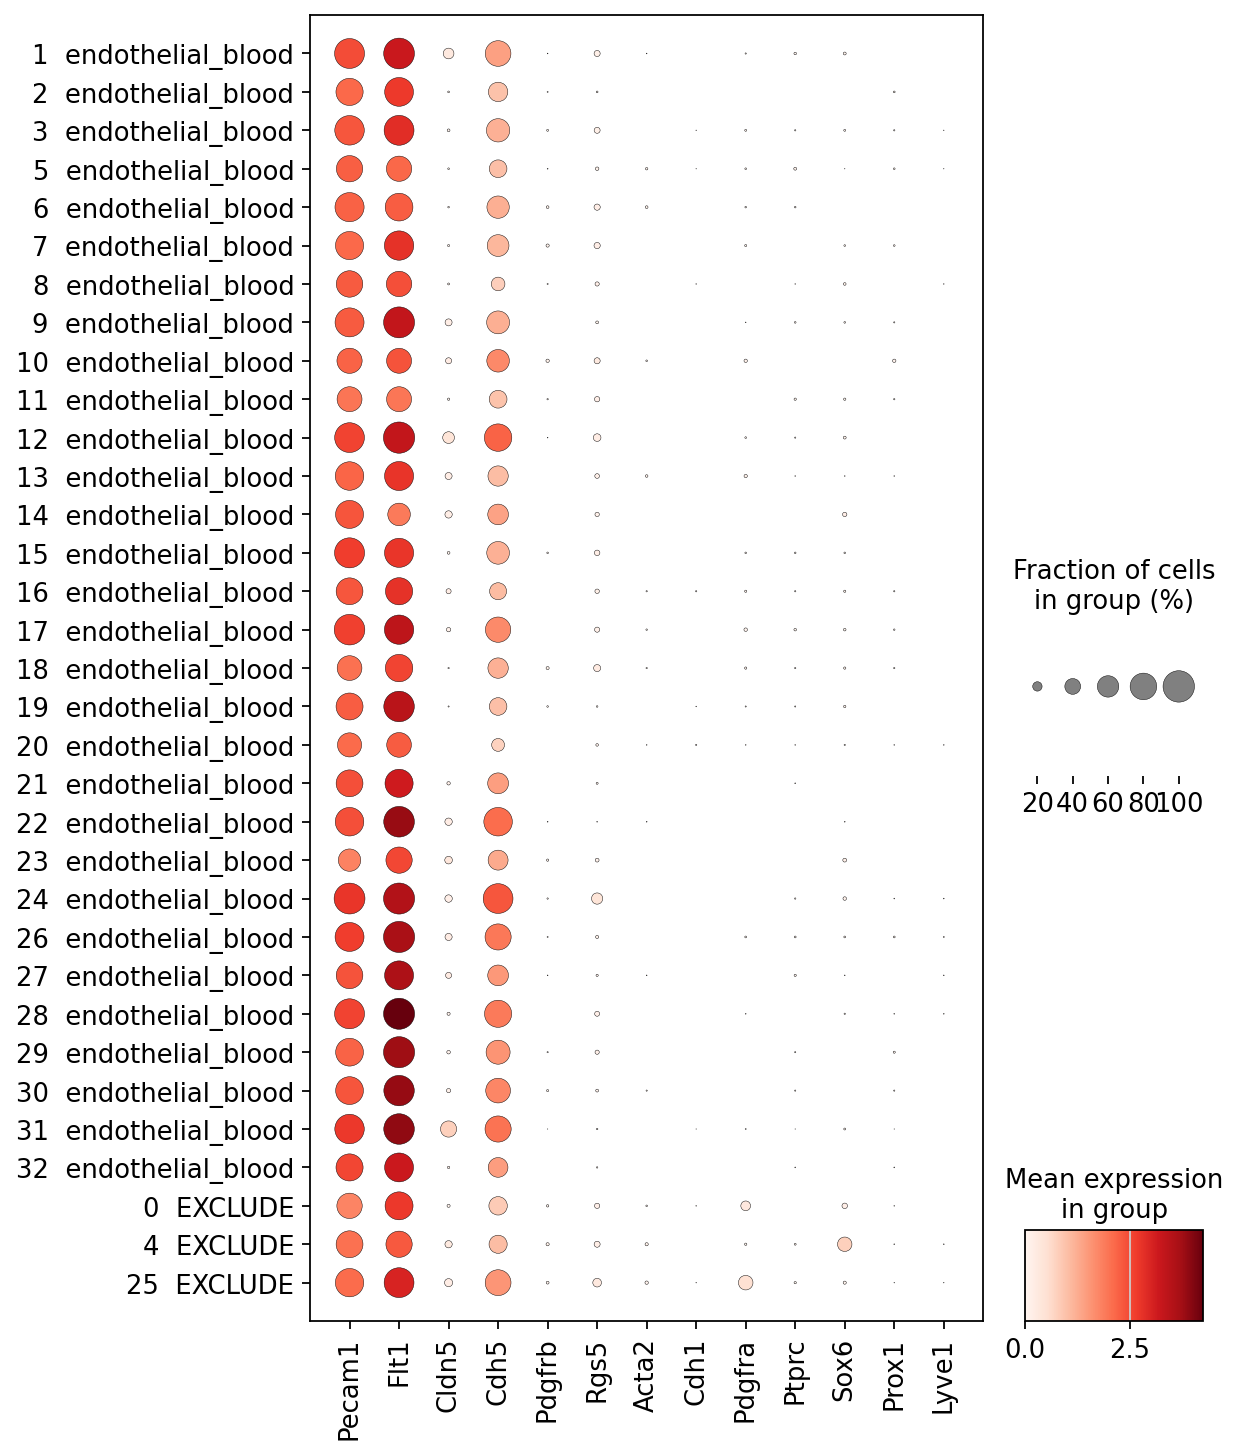

In [5]:
def sort_key(c):
    return (labels[c] == "EXCLUDE", labels[c], int(c) if c.isdigit() else c)

order = sorted(in_object, key=sort_key)
expr.obs["cluster_labelled"] = pd.Categorical(
    [f"{c}  {labels[c]}" for c in expr.obs["cluster"]],
    categories=[f"{c}  {labels[c]}" for c in order])
sc.pl.dotplot(expr, genes, groupby="cluster_labelled", standard_scale=None,
              figsize=(0.32 * len(genes) + 3, 0.28 * len(order) + 1.5))

## 4. QC per cluster

Median DoubletDetection score and genes per nucleus per cluster, with the lineage
median for reference (the CSV notes quote the lineage's doublet 75th and genes 25th
percentiles, from `tools/cluster_marker_table.py`). A high doublet score together
with markers of another lineage (section 6) is what an EXCLUDE call rests on; a
moderate score alone is not (cycling clusters score around 1 throughout this
dataset).

In [6]:
qc_cols = [c for c in ("doubletdetection_doublet_score", "n_genes_by_counts",
                       "total_counts") if c in adata.obs]
qc = adata.obs.groupby("cluster", observed=True)[qc_cols].median().loc[order]
qc.insert(0, "n", adata.obs["cluster"].value_counts().loc[order])
qc.insert(1, "label", labels.loc[order])
qc.loc["lineage median"] = [adata.n_obs, ""] + list(adata.obs[qc_cols].median())
qc.round(2)

,n,label,doubletdetection_doublet_score,n_genes_by_counts,total_counts
cluster,,,,,
1,143,endothelial_blood,0.09,2187.0,3798.0
2,91,endothelial_blood,0.00,1585.0,2628.0
3,201,endothelial_blood,0.22,2203.0,3927.0
5,241,endothelial_blood,0.00,981.0,1485.0
6,52,endothelial_blood,0.02,1812.0,3090.5
7,147,endothelial_blood,0.12,1854.0,2884.0
8,161,endothelial_blood,0.00,820.0,1131.0
9,148,endothelial_blood,0.00,1770.5,2836.5
10,98,endothelial_blood,0.00,933.5,1335.0


## 5. UMAP by cluster and by label

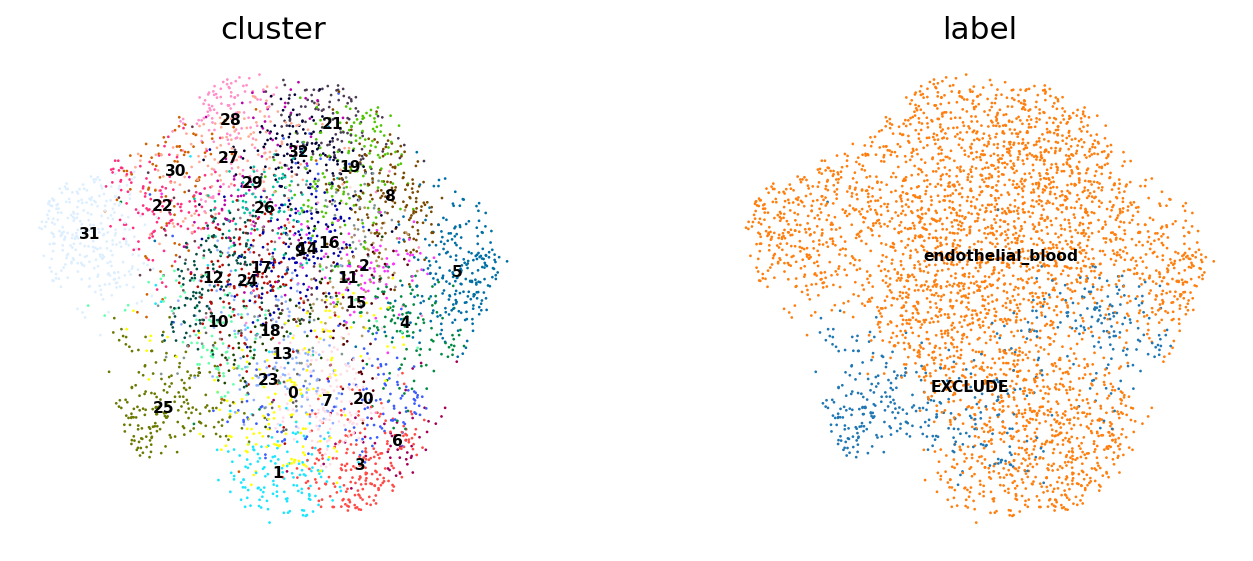

In [7]:
umap_key = next((k for k in ("X_umap_scVI", "X_umap") if k in adata.obsm), None)
if umap_key is None:
    latent_key = next(k for k in adata.obsm if "scVI" in k or "scvi" in k)
    sc.pp.neighbors(adata, use_rep=latent_key, n_neighbors=15, random_state=0)
    sc.tl.umap(adata, random_state=0)
    umap_key = "X_umap"
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sc.pl.embedding(adata, basis=umap_key, color=["cluster", "label"], legend_loc="on data",
                    legend_fontsize=7, size=6, ncols=2, wspace=0.25)

## 6. EXCLUDE clusters

Detection of each lineage's markers inside the excluded clusters, next to the
lineage-wide detection; a cluster is excluded when it carries another lineage's
programme (doublets) or too little RNA to call.

In [8]:
excluded = [c for c in order if labels[c] == "EXCLUDE"]
if excluded:
    detected = pd.DataFrame(
        {c: np.asarray((expr[expr.obs["cluster"] == c, genes].X > 0).mean(0)).ravel()
         for c in excluded},
        index=genes)
    detected["lineage"] = np.asarray((expr[:, genes].X > 0).mean(0)).ravel()
    display(detected.round(2).T)
else:
    print("no EXCLUDE clusters in this table")

,Pecam1,Flt1,Cldn5,Cdh5,Pdgfrb,Rgs5,Acta2,Cdh1,Pdgfra,Ptprc,Sox6,Prox1,Lyve1
0,0.75,0.86,0.05,0.49,0.03,0.09,0.02,0.01,0.21,0.00,0.10,0.01,0.00
4,0.81,0.79,0.14,0.48,0.05,0.11,0.05,0.00,0.03,0.02,0.35,0.01,0.01
25,0.87,0.93,0.16,0.77,0.04,0.18,0.05,0.01,0.36,0.03,0.05,0.01,0.01
lineage,0.85,0.89,0.11,0.63,0.02,0.08,0.01,0.00,0.04,0.01,0.04,0.01,0.00
